In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# Label untuk kolom Kelamin (hanya untuk tampilan)
label_kelamin = {0: "Perempuan", 1: "Laki-laki"}

def tampil(data):
    """Kembalikan salinan data dengan Kelamin berupa teks, tanpa mengubah data asli."""
    data = data.copy()
    if "Kelamin" in data.columns:
        data["Kelamin"] = data["Kelamin"].map(label_kelamin)
    return data

In [17]:
df = pd.read_csv("/content/drive/MyDrive/MesinLearning/Praktikum04/Data/calonpembelimobil.csv")
print("5 Baris Pertama Data")
display(tampil(df.head()))

5 Baris Pertama Data


,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,Perempuan,0,240,1
1,2,49,2,Laki-laki,1,100,0
2,3,52,1,Perempuan,2,250,1
3,4,26,2,Laki-laki,1,130,0
4,5,45,3,Perempuan,2,237,1


In [18]:
print("Jumlah data (baris)    :", df.shape[0])
print("Jumlah atribut (kolom) :", df.shape[1])
print("Nama atribut           :", list(df.columns))
print("Variabel target        : Beli_Mobil")

Jumlah data (baris)    : 1000
Jumlah atribut (kolom) : 7
Nama atribut           : ['ID', 'Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan', 'Beli_Mobil']
Variabel target        : Beli_Mobil


In [19]:
# Informasi umum dataset (tipe data dan jumlah data non-null)
print("--- Informasi Dataset ---")
df.info()

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB


In [20]:
# Distribusi variabel target
print("--- Distribusi Target (Beli_Mobil) ---")
print(df["Beli_Mobil"].value_counts().sort_index())
print()
print("Proporsi (%):")
print((df["Beli_Mobil"].value_counts(normalize=True).sort_index() * 100).round(2))

--- Distribusi Target (Beli_Mobil) ---
Beli_Mobil
0    367
1    633
Name: count, dtype: int64

Proporsi (%):
Beli_Mobil
0    36.7
1    63.3
Name: proportion, dtype: float64


In [21]:
print("Cek Missing Value")
print(df.isnull().sum())

print("\nCek Duplikasi (seluruh kolom)")
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Apakah ID unik?      :", df["ID"].is_unique)

Cek Missing Value
ID                0
Usia              0
Status            0
Kelamin           0
Memiliki_Mobil    0
Penghasilan       0
Beli_Mobil        0
dtype: int64

Cek Duplikasi (seluruh kolom)
Jumlah baris duplikat: 0
Apakah ID unik?      : True


In [22]:
print("--- Nilai Unik Kolom Kategorikal/Diskrit ---")
for kolom in ["Status", "Kelamin", "Memiliki_Mobil", "Beli_Mobil"]:
    nilai = sorted(df[kolom].unique().tolist())
    if kolom == "Kelamin":                       # tampilkan sebagai teks, bukan 0/1
        nilai = [label_kelamin[v] for v in nilai]
    print(f"{kolom:15s}:", nilai)

print("\n--- Statistik Deskriptif Kolom Numerik ---")
display(df[["Usia", "Penghasilan"]].describe())

--- Nilai Unik Kolom Kategorikal/Diskrit ---
Status         : [0, 1, 2, 3]
Kelamin        : ['Perempuan', 'Laki-laki']
Memiliki_Mobil : [0, 1, 2, 3, 4]
Beli_Mobil     : [0, 1]

--- Statistik Deskriptif Kolom Numerik ---


,Usia,Penghasilan
count,1000.000000,1000.00000
mean,43.532000,270.09000
std,12.672078,95.23681
min,24.000000,95.00000
25%,33.000000,187.00000
50%,43.000000,258.50000
75%,53.000000,352.25000
max,164.000000,490.00000


In [23]:
# Usia maksimum terlihat tidak wajar, periksa nilai terbesarnya
print("5 nilai Usia terbesar:", sorted(df["Usia"].tolist())[-5:])
print("\nData dengan Usia > 100 tahun:")
display(tampil(df[df["Usia"] > 100]))

5 nilai Usia terbesar: [65, 65, 65, 131, 164]

Data dengan Usia > 100 tahun:


,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
200,201,164,0,Perempuan,0,100,0
227,228,131,2,Laki-laki,0,100,0


In [24]:
jumlah_awal = df.shape[0]

# 1) Hapus data dengan Usia tidak valid (> 100 tahun)
df_clean = df[df["Usia"] <= 100].copy()

# 2) Buang kolom ID karena hanya identifier
df_clean = df_clean.drop(columns=["ID"])

print("Jumlah data sebelum preprocessing:", jumlah_awal)
print("Jumlah data setelah preprocessing:", df_clean.shape[0])
print("Jumlah data yang dihapus         :", jumlah_awal - df_clean.shape[0])
print("Kolom setelah preprocessing      :", list(df_clean.columns))
print("\nUsia minimum & maksimum sekarang :", df_clean["Usia"].min(), "&", df_clean["Usia"].max())
display(tampil(df_clean.head()))

Jumlah data sebelum preprocessing: 1000
Jumlah data setelah preprocessing: 998
Jumlah data yang dihapus         : 2
Kolom setelah preprocessing      : ['Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan', 'Beli_Mobil']

Usia minimum & maksimum sekarang : 24 & 65


,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,32,1,Perempuan,0,240,1
1,49,2,Laki-laki,1,100,0
2,52,1,Perempuan,2,250,1
3,26,2,Laki-laki,1,130,0
4,45,3,Perempuan,2,237,1


In [25]:
df_encoded = pd.get_dummies(df_clean, columns=["Status"], prefix="Status", dtype=int)

print("Kolom sebelum encoding:", list(df_clean.columns))
print("Kolom sesudah encoding:", list(df_encoded.columns))
print("\nContoh data setelah encoding:")
display(tampil(df_encoded.head()))

Kolom sebelum encoding: ['Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan', 'Beli_Mobil']
Kolom sesudah encoding: ['Usia', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan', 'Beli_Mobil', 'Status_0', 'Status_1', 'Status_2', 'Status_3']

Contoh data setelah encoding:


,Usia,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil,Status_0,Status_1,Status_2,Status_3
0,32,Perempuan,0,240,1,0,1,0,0
1,49,Laki-laki,1,100,0,0,0,1,0
2,52,Perempuan,2,250,1,0,1,0,0
3,26,Laki-laki,1,130,0,0,0,1,0
4,45,Perempuan,2,237,1,0,0,0,1


In [26]:
feature_num = ["Usia", "Memiliki_Mobil", "Penghasilan"]            # numerik -> di-scaling
feature_bin = ["Kelamin", "Status_0", "Status_1", "Status_2", "Status_3"]  # biner/one-hot -> dibiarkan

X = df_encoded[feature_num + feature_bin]
y = df_encoded["Beli_Mobil"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Fitur (X):", list(X.columns))
print("Target (y): Beli_Mobil")
display(tampil(X.head()))

X shape: (998, 8)
y shape: (998,)
Fitur (X): ['Usia', 'Memiliki_Mobil', 'Penghasilan', 'Kelamin', 'Status_0', 'Status_1', 'Status_2', 'Status_3']
Target (y): Beli_Mobil


,Usia,Memiliki_Mobil,Penghasilan,Kelamin,Status_0,Status_1,Status_2,Status_3
0,32,0,240,Perempuan,0,1,0,0
1,49,1,100,Laki-laki,0,0,1,0
2,52,2,250,Perempuan,0,1,0,0
3,26,1,130,Laki-laki,0,0,1,0
4,45,2,237,Perempuan,0,0,0,1


In [27]:
# Langkah 1: sisihkan 10% data sebagai data baru (tidak dipakai saat training)
X_dev, X_baru, y_dev, y_baru = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

# Langkah 2: bagi sisanya menjadi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_dev, y_dev, test_size=0.2, random_state=42, stratify=y_dev
)

print("Total data setelah preprocessing:", X.shape[0])
print("Jumlah data baru (hold-out)     :", X_baru.shape[0])
print("Jumlah data latih (training)    :", X_train.shape[0], "->", X_train.shape)
print("Jumlah data uji (testing)       :", X_test.shape[0], "->", X_test.shape)
print("\nProporsi Beli_Mobil data latih (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))
print("\nProporsi Beli_Mobil data uji (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Total data setelah preprocessing: 998
Jumlah data baru (hold-out)     : 100
Jumlah data latih (training)    : 718 -> (718, 8)
Jumlah data uji (testing)       : 180 -> (180, 8)

Proporsi Beli_Mobil data latih (%):
Beli_Mobil
0    36.49
1    63.51
Name: proportion, dtype: float64

Proporsi Beli_Mobil data uji (%):
Beli_Mobil
0    36.67
1    63.33
Name: proportion, dtype: float64


In [28]:
print("Contoh Data Training (X_train):")
display(tampil(X_train.head()))
print("Contoh Data Testing (X_test):")
display(tampil(X_test.head()))

Contoh Data Training (X_train):


,Usia,Memiliki_Mobil,Penghasilan,Kelamin,Status_0,Status_1,Status_2,Status_3
271,44,1,314,Laki-laki,1,0,0,0
925,59,2,140,Perempuan,1,0,0,0
600,49,1,326,Laki-laki,1,0,0,0
183,54,3,400,Perempuan,0,0,1,0
375,54,0,147,Laki-laki,0,0,0,1


Contoh Data Testing (X_test):


,Usia,Memiliki_Mobil,Penghasilan,Kelamin,Status_0,Status_1,Status_2,Status_3
901,36,2,445,Laki-laki,0,1,0,0
60,52,0,172,Laki-laki,0,1,0,0
85,48,1,288,Perempuan,0,0,1,0
468,38,1,167,Perempuan,0,0,0,1
286,28,1,427,Laki-laki,0,0,1,0


In [29]:
preprocess = ColumnTransformer(
    transformers=[("num", StandardScaler(), feature_num),("bin", "passthrough", feature_bin),],remainder="drop",)
model = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=42)

clf = Pipeline([("preprocess", preprocess), ("model", model)])
print(clf)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Usia', 'Memiliki_Mobil',
                                                   'Penghasilan']),
                                                 ('bin', 'passthrough',
                                                  ['Kelamin', 'Status_0',
                                                   'Status_1', 'Status_2',
                                                   'Status_3'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])


In [30]:
clf.fit(X_train, y_train)
print("Model Logistic Regression berhasil dilatih.")
print("Jumlah data latih yang digunakan:", X_train.shape[0])
print("Jumlah iterasi sampai konvergen :", clf.named_steps["model"].n_iter_[0])

Model Logistic Regression berhasil dilatih.
Jumlah data latih yang digunakan: 718
Jumlah iterasi sampai konvergen : 14


In [31]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]   # probabilitas kelas 1 (membeli)

hasil_prediksi = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred,
    "Prob_Beli (kelas 1)": y_prob.round(4),
})
print("Perbandingan Aktual vs Prediksi (10 data uji pertama):")
display(hasil_prediksi.head(10))

Perbandingan Aktual vs Prediksi (10 data uji pertama):


,Aktual,Prediksi,Prob_Beli (kelas 1)
0,1,1,1.0000
1,0,0,0.0525
2,1,1,0.9619
3,0,0,0.1302
4,1,1,0.9999
5,0,0,0.1280
6,1,1,0.9980
7,0,0,0.2700
8,0,0,0.1275
9,1,1,0.9743


In [32]:
print("--- Hasil Evaluasi Metrik (data uji) ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")

--- Hasil Evaluasi Metrik (data uji) ---
Accuracy  : 0.9278
Precision : 0.9810
Recall    : 0.9035
F1-Score  : 0.9406


Confusion Matrix:
                        Prediksi: Tidak Beli (0)  Prediksi: Beli (1)
Aktual: Tidak Beli (0)                        64                   2
Aktual: Beli (1)                              11                 103
64, FP = 2, FN = 11, TP = 103


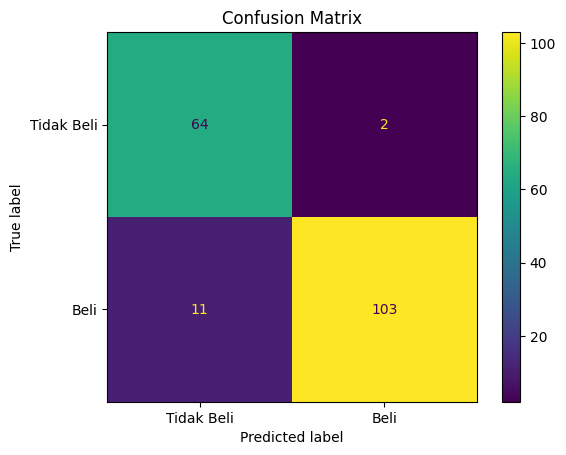

In [33]:
# Confusion Matrix (baris = aktual, kolom = prediksi)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:")
print(pd.DataFrame(cm,
                   index=["Aktual: Tidak Beli (0)", "Aktual: Beli (1)"],
                   columns=["Prediksi: Tidak Beli (0)", "Prediksi: Beli (1)"]))

tn, fp, fn, tp = cm.ravel()
print(f"{tn}, FP = {fp}, FN = {fn}, TP = {tp}")

ConfusionMatrixDisplay(cm, display_labels=["Tidak Beli", "Beli"]).plot(values_format="d")
plt.title("Confusion Matrix")
plt.show()

In [34]:
print("--- Classification Report ---")
print(classification_report(y_test, y_pred,target_names=["Tidak Beli (0)", "Beli (1)"]))

--- Classification Report ---
                precision    recall  f1-score   support

Tidak Beli (0)       0.85      0.97      0.91        66
      Beli (1)       0.98      0.90      0.94       114

      accuracy                           0.93       180
     macro avg       0.92      0.94      0.92       180
  weighted avg       0.93      0.93      0.93       180



In [35]:
# Ambil data baru (bentuk asli, sebelum encoding) dari dataset hasil preprocessing
kolom_asli = ["Usia", "Status", "Kelamin", "Memiliki_Mobil", "Penghasilan"]
data_baru = df_clean.loc[X_baru.index, kolom_asli]
aktual_baru = df_clean.loc[X_baru.index, "Beli_Mobil"]

print("Jumlah data baru:", data_baru.shape[0])
print("Contoh data calon pembeli baru (10 baris pertama):")
display(tampil(data_baru.head(10)))

Jumlah data baru: 100
Contoh data calon pembeli baru (10 baris pertama):


,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan
583,42,3,Perempuan,2,426
305,44,1,Laki-laki,2,261
416,32,1,Laki-laki,0,160
957,31,2,Perempuan,0,136
994,47,3,Perempuan,1,135
91,24,0,Laki-laki,0,129
41,24,0,Laki-laki,0,95
482,65,1,Perempuan,2,421
374,25,0,Laki-laki,1,155
105,26,3,Laki-laki,1,172


In [36]:
# Preprocessing data baru: aturan encoding sama dengan data training
data_baru_enc = pd.get_dummies(data_baru, columns=["Status"], prefix="Status", dtype=int)
data_baru_enc = data_baru_enc.reindex(columns=X.columns, fill_value=0)   # struktur kolom = X

print("Struktur kolom sama dengan X training:", list(data_baru_enc.columns) == list(X.columns))
display(tampil(data_baru_enc.head()))

Struktur kolom sama dengan X training: True


,Usia,Memiliki_Mobil,Penghasilan,Kelamin,Status_0,Status_1,Status_2,Status_3
583,42,2,426,Perempuan,0,0,0,1
305,44,2,261,Laki-laki,0,1,0,0
416,32,0,160,Laki-laki,0,1,0,0
957,31,0,136,Perempuan,0,0,1,0
994,47,1,135,Perempuan,0,0,0,1


In [37]:
pred_baru = clf.predict(data_baru_enc)
prob_baru = clf.predict_proba(data_baru_enc)

hasil_baru = data_baru.copy()
hasil_baru["Prob_Tidak_Beli (0)"] = prob_baru[:, 0].round(4)
hasil_baru["Prob_Beli (1)"] = prob_baru[:, 1].round(4)
hasil_baru["Prediksi"] = pred_baru
hasil_baru["Keterangan"] = np.where(pred_baru == 1, "Membeli Mobil", "Tidak Membeli Mobil")
hasil_baru["Aktual"] = aktual_baru.values
hasil_baru["Benar?"] = np.where(pred_baru == aktual_baru.values, "Ya", "Tidak")

print("--- Hasil Prediksi Data Baru (10 baris pertama) ---")
display(tampil(hasil_baru.head(10)))

--- Hasil Prediksi Data Baru (10 baris pertama) ---


,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prob_Tidak_Beli (0),Prob_Beli (1),Prediksi,Keterangan,Aktual,Benar?
583,42,3,Perempuan,2,426,0.0000,1.0000,1,Membeli Mobil,1,Ya
305,44,1,Laki-laki,2,261,0.1727,0.8273,1,Membeli Mobil,1,Ya
416,32,1,Laki-laki,0,160,0.9637,0.0363,0,Tidak Membeli Mobil,0,Ya
957,31,2,Perempuan,0,136,0.9779,0.0221,0,Tidak Membeli Mobil,0,Ya
994,47,3,Perempuan,1,135,0.9693,0.0307,0,Tidak Membeli Mobil,0,Ya
91,24,0,Laki-laki,0,129,0.9906,0.0094,0,Tidak Membeli Mobil,0,Ya
41,24,0,Laki-laki,0,95,0.9980,0.0020,0,Tidak Membeli Mobil,0,Ya
482,65,1,Perempuan,2,421,0.0001,0.9999,1,Membeli Mobil,1,Ya
374,25,0,Laki-laki,1,155,0.9651,0.0349,0,Tidak Membeli Mobil,0,Ya
105,26,3,Laki-laki,1,172,0.9274,0.0726,0,Tidak Membeli Mobil,0,Ya


In [38]:
# Data baru buatan sendiri (5 calon pembeli), Kelamin ditulis dengan teks agar mudah dibaca
data_manual = pd.DataFrame({
    "Usia":           [45, 28, 52, 23, 38],
    "Status":         [1, 2, 3, 0, 1],
    "Kelamin":        ["Perempuan", "Laki-laki", "Perempuan", "Laki-laki", "Laki-laki"],
    "Memiliki_Mobil": [2, 0, 2, 0, 1],
    "Penghasilan":    [420, 110, 380, 100, 250]
})

# Ubah teks Kelamin kembali ke kode 0/1 agar sesuai format data latih
kode_kelamin = {nama: kode for kode, nama in label_kelamin.items()}
data_manual_model = data_manual.copy()
data_manual_model["Kelamin"] = data_manual_model["Kelamin"].map(kode_kelamin)

# Preprocessing sama seperti data latih: one-hot Status + samakan struktur kolom dengan X
data_manual_enc = pd.get_dummies(data_manual_model, columns=["Status"], prefix="Status", dtype=int)
data_manual_enc = data_manual_enc.reindex(columns=X.columns, fill_value=0)

# Prediksi
pred_manual = clf.predict(data_manual_enc)
prob_manual = clf.predict_proba(data_manual_enc)[:, 1]

hasil_manual = data_manual.copy()   # Kelamin tetap berupa teks
hasil_manual["Prob_Beli (1)"] = prob_manual.round(4)
hasil_manual["Prediksi"] = pred_manual
hasil_manual["Keterangan"] = np.where(pred_manual == 1, "Membeli Mobil", "Tidak Membeli Mobil")

print("--- Hasil Prediksi Data Baru Buatan Sendiri ---")
display(hasil_manual)

--- Hasil Prediksi Data Baru Buatan Sendiri ---


,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prob_Beli (1),Prediksi,Keterangan
0,45,1,Perempuan,2,420,0.9999,1,Membeli Mobil
1,28,2,Laki-laki,0,110,0.0026,0,Tidak Membeli Mobil
2,52,3,Perempuan,2,380,0.9997,1,Membeli Mobil
3,23,0,Laki-laki,0,100,0.0025,0,Tidak Membeli Mobil
4,38,1,Laki-laki,1,250,0.7248,1,Membeli Mobil


In [39]:
# Ringkasan performa model pada data baru
print("--- Ringkasan Pengujian Data Baru ---")
print("Jumlah data baru   :", len(aktual_baru))
print("Prediksi benar     :", (pred_baru == aktual_baru.values).sum())
print("Prediksi salah     :", (pred_baru != aktual_baru.values).sum())
print(f"Accuracy  : {accuracy_score(aktual_baru, pred_baru):.4f}")
print(f"Precision : {precision_score(aktual_baru, pred_baru, pos_label=1, zero_division=0):.4f}")
print(f"Recall    : {recall_score(aktual_baru, pred_baru, pos_label=1, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(aktual_baru, pred_baru, pos_label=1, zero_division=0):.4f}")

cm_baru = confusion_matrix(aktual_baru, pred_baru, labels=[0, 1])
print("\nConfusion Matrix Data Baru:")
print(pd.DataFrame(cm_baru,
                   index=["Aktual: Tidak Beli (0)", "Aktual: Beli (1)"],
                   columns=["Prediksi: Tidak Beli (0)", "Prediksi: Beli (1)"]))

--- Ringkasan Pengujian Data Baru ---
Jumlah data baru   : 100
Prediksi benar     : 95
Prediksi salah     : 5
Accuracy  : 0.9500
Precision : 0.9833
Recall    : 0.9365
F1-Score  : 0.9593

Confusion Matrix Data Baru:
                        Prediksi: Tidak Beli (0)  Prediksi: Beli (1)
Aktual: Tidak Beli (0)                        36                   1
Aktual: Beli (1)                               4                  59
